# 02 — Analyse exploratoire

**Projet Horizon : décrochage et tutorat** — tâche DA-08.

Ce notebook décrit les étudiants, la censure, la distribution des durées de suivi, l'activité et l'entrée en tutorat, pour préparer l'analyse de survie (SV-01) et la partie causale (CA-01).
Il lit les fichiers de `data/processed/` produits par `python run_all.py` (il ne relance pas le pipeline) ; les calculs sont dans `src/eda.py`.

**Description seulement** : aucun modèle, aucun test statistique. On ne compare pas le décrochage entre groupes (boursiers, filières, tutorés…) : avec la censure, un taux brut par groupe serait biaisé. Ces comparaisons viendront en SV-01, avec Kaplan-Meier.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Le notebook est dans notebooks/ : on remonte jusqu'à la racine du dépôt (dossier qui
# contient src/config.py) pour pouvoir importer src/, quel que soit le dossier de lancement.
racine = Path.cwd()
while not (racine / "src" / "config.py").exists():
    racine = racine.parent
sys.path.insert(0, str(racine))

from src import config, eda

pd.set_option("display.max_rows", 80)
config.DOSSIER_FIGURES.mkdir(parents=True, exist_ok=True)


def enregistrer(figure, nom):
    """Enregistre une figure en PNG dans docs/figures/ et l'affiche."""
    figure.tight_layout()
    figure.savefig(config.DOSSIER_FIGURES / nom, dpi=120)
    plt.show()


def pct(x, decimales=1):
    """Nombre au format français, ex. 41,1."""
    return f"{x:.{decimales}f}".replace(".", ",")


base, periode = eda.lire_bases()
print(f"{len(base)} étudiants, {len(periode)} lignes étudiant × semaine.")

5000 étudiants, 121938 lignes étudiant × semaine.


## 1. Profil des étudiants par cohorte

In [2]:
profil = eda.profil_par_cohorte(base)


def cellule_profil(ligne):
    """Texte d'une case : « moyenne (écart-type) » ou « % (effectif) »."""
    if pd.notna(ligne["moyenne"]):
        return f"{pct(ligne['moyenne'], 2)} ({pct(ligne['ecart_type'], 2)})"
    return f"{pct(ligne['pourcentage'])} % ({ligne['effectif']})"


profil["valeur"] = profil.apply(cellule_profil, axis=1)
tableau_profil = profil.pivot_table(index=["variable", "modalite"], columns="cohorte", values="valeur",
                                    aggfunc="first", sort=False)
display(tableau_profil)

qualitatives = profil[profil["moyenne"].isna()].pivot_table(index=["variable", "modalite"], columns="cohorte",
                                                             values="pourcentage")
ecarts = (qualitatives[2024] - qualitatives[2025]).abs()
plus_grand = ecarts.idxmax()
moyennes = profil[profil["moyenne"].notna()].set_index(["variable", "cohorte"])["moyenne"]
oui = qualitatives.xs("Oui", level="modalite")
print(f"Les deux cohortes ont un profil très proche : l'écart le plus grand entre elles, sur toutes les modalités, "
      f"est de {pct(ecarts.max())} point(s) de pourcentage ({plus_grand[0]} = {plus_grand[1]}). "
      f"Âge moyen : {pct(moyennes['age', 2024], 2)} ans en 2024 et {pct(moyennes['age', 2025], 2)} en 2025 ; "
      f"boursiers : {pct(oui.loc['boursier', 2024])} % et {pct(oui.loc['boursier', 2025])} % ; "
      f"emploi en parallèle : {pct(oui.loc['emploi_parallele', 2024])} % et {pct(oui.loc['emploi_parallele', 2025])} % ; "
      f"note du bac moyenne : {pct(moyennes['note_bac', 2024], 2)} et {pct(moyennes['note_bac', 2025], 2)}. "
      "C'est important pour la validation imposée (modèle appris sur 2024, testé sur 2025) : "
      "les étudiants de test ressemblent à ceux de l'entraînement.")

cohorte                                           2024           2025
variable           modalite                                          
genre              F                     46,4 % (1157)  44,4 % (1113)
                   M                     53,6 % (1338)  55,6 % (1392)
age                moyenne (écart-type)   20,18 (1,57)   20,17 (1,56)
boursier           Non                   58,9 % (1470)  58,0 % (1453)
                   Oui                   41,1 % (1025)  42,0 % (1052)
filiere            Communication          15,3 % (382)   15,2 % (381)
                   Droit                  16,3 % (407)   16,5 % (414)
                   Gestion                24,5 % (611)   25,0 % (625)
                   Génie civil            15,7 % (391)   14,0 % (351)
                   Informatique           28,2 % (704)   29,3 % (734)
mention_bac        Assez bien             29,8 % (743)   29,3 % (733)
                   Bien                   17,7 % (442)   18,3 % (459)
                   Passable              45,7 % (1141)  46,1 % (1155)
                   Très bien               6,8 % (169)    6,3 % (158)
note_bac           moyenne (écart-type)   12,73 (2,02)   12,69 (1,98)
region_origine     Dakar                  39,6 % (988)  40,1 % (1004)
                   Diourbel                7,7 % (191)    6,8 % (170)
                   Fatick                  4,2 % (105)     3,7 % (92)
                   Kaffrine                 2,2 % (54)     1,8 % (45)
                   Kaolack                 5,0 % (124)    6,1 % (153)
                   Kolda                    2,5 % (62)     3,2 % (80)
                   Kédougou                 1,7 % (42)     1,7 % (42)
                   Louga                   4,6 % (116)    4,4 % (111)
                   Matam                    2,1 % (53)     1,9 % (48)
                   Saint-Louis             6,5 % (162)    6,3 % (158)
                   Sédhiou                  2,0 % (49)     1,6 % (40)
                   Tambacounda              2,8 % (71)     3,5 % (87)
                   Thiès                  12,3 % (306)   12,2 % (305)
                   Ziguinchor              4,8 % (121)    5,2 % (131)
                   (manquant)               2,0 % (51)     1,6 % (39)
distance_campus_km moyenne (écart-type)  20,00 (29,76)  20,58 (33,89)
emploi_parallele   Non                   77,2 % (1927)  76,9 % (1926)
                   Oui                    18,9 % (471)   19,0 % (476)
                   (manquant)               3,9 % (97)    4,1 % (103)

Les deux cohortes ont un profil très proche : l'écart le plus grand entre elles, sur toutes les modalités, est de 1,9 point(s) de pourcentage (genre = F). Âge moyen : 20,18 ans en 2024 et 20,17 en 2025 ; boursiers : 41,1 % et 42,0 % ; emploi en parallèle : 18,9 % et 19,0 % ; note du bac moyenne : 12,73 et 12,69. C'est important pour la validation imposée (modèle appris sur 2024, testé sur 2025) : les étudiants de test ressemblent à ceux de l'entraînement.


## 2. Valeurs manquantes des covariables de la rentrée

In [3]:
manquants = eda.manquants_covariables(base)
manquants["pourcentage"] = manquants["pourcentage"].round(1)
display(manquants)
avec_manquants = manquants[manquants["manquants"] > 0].sort_values("manquants", ascending=False)
liste = ", ".join(f"{variable} ({int(n)})" for variable, n in avec_manquants["manquants"].items())
print(f"{len(avec_manquants)} covariables sur {len(manquants)} ont des valeurs manquantes : {liste}. "
      f"Au plus {pct(manquants['pourcentage'].max())} % des étudiants pour une variable : c'est peu. "
      "Ces valeurs restent manquantes dans data/processed/ ; elles seront imputées dans les modèles, "
      "avec des statistiques calculées sur la cohorte d'entraînement (2024) seulement.")

,manquants,pourcentage
cohorte,0,0.0
genre,0,0.0
age,84,1.7
boursier,0,0.0
filiere,0,0.0
mention_bac,0,0.0
note_bac,18,0.4
region_origine,90,1.8
distance_campus_km,25,0.5
emploi_parallele,200,4.0


5 covariables sur 10 ont des valeurs manquantes : emploi_parallele (200), region_origine (90), age (84), distance_campus_km (25), note_bac (18). Au plus 4,0 % des étudiants pour une variable : c'est peu. Ces valeurs restent manquantes dans data/processed/ ; elles seront imputées dans les modèles, avec des statistiques calculées sur la cohorte d'entraînement (2024) seulement.


## 3. Décrochage et censure

In [4]:
par_type, synthese = eda.repartition_evenements(base)
par_type["pourcentage"] = par_type["pourcentage"].round(1)
synthese["pourcentage"] = synthese["pourcentage"].round(1)
display(par_type)
display(synthese)
quartiles_T = base["T"].quantile([0.25, 0.5])
print(f"{synthese.loc['E = 0 (censure)', 'effectif']} étudiants ({pct(synthese.loc['E = 0 (censure)', 'pourcentage'])} %) "
      "sont censurés : on ne les voit pas décrocher pendant leur suivi (toujours inscrits à la semaine 30, transférés "
      "ou perdus de vue). Ils restent dans l'analyse, car ils apportent l'information « n'a pas décroché pendant "
      f"T semaines ». La durée de suivi T a un premier quartile de {quartiles_T[0.25]:.0f} semaines et une médiane de "
      f"{quartiles_T[0.5]:.0f} : plus de la moitié des étudiants sont suivis jusqu'au bout.")

,effectif,pourcentage,E
type_evenement,,,
fin_de_suivi,3441,68.8,0
abandon_declare,1004,20.1,1
decrochage_silencieux,408,8.2,1
transfert,117,2.3,0
abandon_sans_date,22,0.4,1
abandon_date_invalide,6,0.1,1
perdu_de_vue,2,0.0,0


,effectif,pourcentage
E = 1 (décrochage),1440,28.8
E = 0 (censure),3560,71.2


3560 étudiants (71,2 %) sont censurés : on ne les voit pas décrocher pendant leur suivi (toujours inscrits à la semaine 30, transférés ou perdus de vue). Ils restent dans l'analyse, car ils apportent l'information « n'a pas décroché pendant T semaines ». La durée de suivi T a un premier quartile de 19 semaines et une médiane de 30 : plus de la moitié des étudiants sont suivis jusqu'au bout.


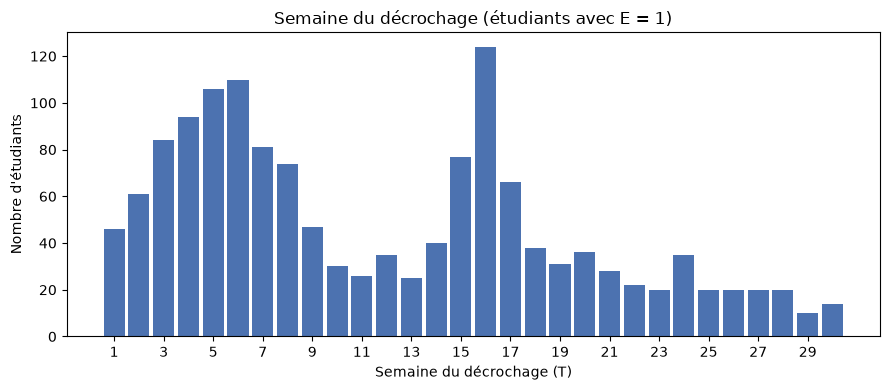

Les semaines où l'on compte le plus de décrochages sont : semaine 16 (124), semaine 6 (110), semaine 5 (106), semaine 4 (94), semaine 3 (84). Ce sont des effectifs bruts : ils ne tiennent pas compte du nombre d'étudiants encore suivis (voir le taux hebdomadaire ci-dessous).


In [5]:
decrochages = base.loc[base["E"] == 1, "T"]
figure, axe = plt.subplots(figsize=(9, 4))
axe.hist(decrochages, bins=range(1, config.N_SEMAINES + 2), align="left", rwidth=0.85, color="#4C72B0")
axe.set_title("Semaine du décrochage (étudiants avec E = 1)")
axe.set_xlabel("Semaine du décrochage (T)")
axe.set_ylabel("Nombre d'étudiants")
axe.set_xticks(range(1, config.N_SEMAINES + 1, 2))
enregistrer(figure, "02_semaines_decrochage.png")

frequentes = decrochages.value_counts().head(5)
liste = ", ".join(f"semaine {s} ({n})" for s, n in frequentes.items())
print(f"Les semaines où l'on compte le plus de décrochages sont : {liste}. "
      "Ce sont des effectifs bruts : ils ne tiennent pas compte du nombre d'étudiants encore suivis "
      "(voir le taux hebdomadaire ci-dessous).")

## 4. Taux de décrochage hebdomadaire

Pour chaque semaine s : nombre de décrochages de la semaine divisé par le nombre d'étudiants **encore suivis au début de la semaine** (T ≥ s). Un étudiant censuré compte parmi les suivis jusqu'à sa semaine T, puis sort du calcul : ce taux tient donc compte de la censure. C'est la seule mesure de décrochage de ce notebook.

,semaine,suivis,decrochages,taux (%)
0,1,5000,46,0.92
1,2,4951,61,1.23
2,3,4884,84,1.72
3,4,4797,94,1.96
4,5,4699,106,2.26
5,6,4589,110,2.40
6,7,4478,81,1.81
7,8,4395,74,1.68
8,9,4320,47,1.09
9,10,4263,30,0.70


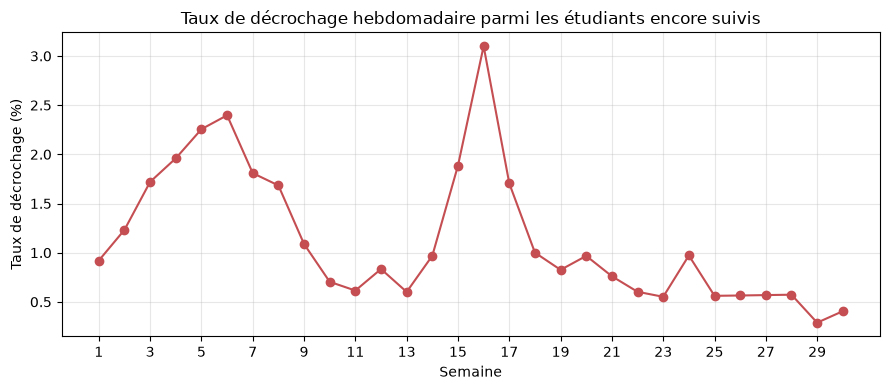

Le risque observé est le plus élevé en semaine 16 : 124 décrochages pour 4000 étudiants encore suivis (3,1 %). Viennent ensuite semaine 6 (2,4 %), semaine 5 (2,3 %), semaine 4 (2,0 %) : en dehors de ce pic, les semaines les plus à risque se situent au début de l'année (semaines 4 à 6). En semaine 1, le taux est de 0,9 % (46 sur 5000) ; il est en moyenne de 1,1 % des semaines 7 à 15 et de 0,7 % des semaines 17 à 30. Ce sont des observations descriptives : l'analyse de survie (SV-01) dira si ces semaines à risque se confirment.


In [6]:
taux = eda.taux_hebdomadaire(base)
taux["taux (%)"] = (100 * taux["taux"]).round(2)
display(taux.drop(columns="taux"))

figure, axe = plt.subplots(figsize=(9, 4))
axe.plot(taux["semaine"], 100 * taux["taux"], marker="o", color="#C44E52")
axe.set_title("Taux de décrochage hebdomadaire parmi les étudiants encore suivis")
axe.set_xlabel("Semaine")
axe.set_ylabel("Taux de décrochage (%)")
axe.set_xticks(range(1, config.N_SEMAINES + 1, 2))
axe.grid(alpha=0.3)
enregistrer(figure, "02_taux_hebdomadaire.png")

classement = taux.sort_values("taux", ascending=False)
pic = classement.iloc[0]
suivantes = ", ".join(f"semaine {int(l.semaine)} ({pct(100 * l.taux)} %)" for l in classement.iloc[1:4].itertuples())
semaine_1 = taux.iloc[0]
milieu = taux[taux["semaine"].between(7, 15)]["taux"].mean()
fin = taux[taux["semaine"].between(17, 30)]["taux"].mean()
print(f"Le risque observé est le plus élevé en semaine {int(pic.semaine)} : {int(pic.decrochages)} décrochages "
      f"pour {int(pic.suivis)} étudiants encore suivis ({pct(100 * pic.taux)} %). Viennent ensuite {suivantes} : "
      f"en dehors de ce pic, les semaines les plus à risque se situent au début de l'année "
      f"(semaines {int(classement.iloc[1:4]['semaine'].min())} à {int(classement.iloc[1:4]['semaine'].max())}). "
      f"En semaine 1, le taux est de {pct(100 * semaine_1.taux)} % ({int(semaine_1.decrochages)} sur {int(semaine_1.suivis)}) ; "
      f"il est en moyenne de {pct(100 * milieu)} % des semaines 7 à 15 et de {pct(100 * fin)} % des semaines 17 à 30. "
      "Ce sont des observations descriptives : l'analyse de survie (SV-01) dira si ces semaines à risque se confirment.")

## 5. Activité au fil des semaines

Moyenne des connexions et part des semaines inactives (0 connexion et 0 devoir), parmi les étudiants encore suivis chaque semaine (lignes de la période-personne, semaines 1 à T).

,semaine,suivis,connexions_moyennes,pct_inactives
0,1,5000,5.87,0.60
1,2,4951,5.89,0.59
2,3,4884,5.91,0.70
3,4,4797,5.99,0.67
4,5,4699,5.98,0.92
5,6,4589,6.03,0.98
6,7,4478,6.01,0.83
7,8,4395,6.07,0.86
8,9,4320,6.13,0.56
9,10,4263,6.10,0.45


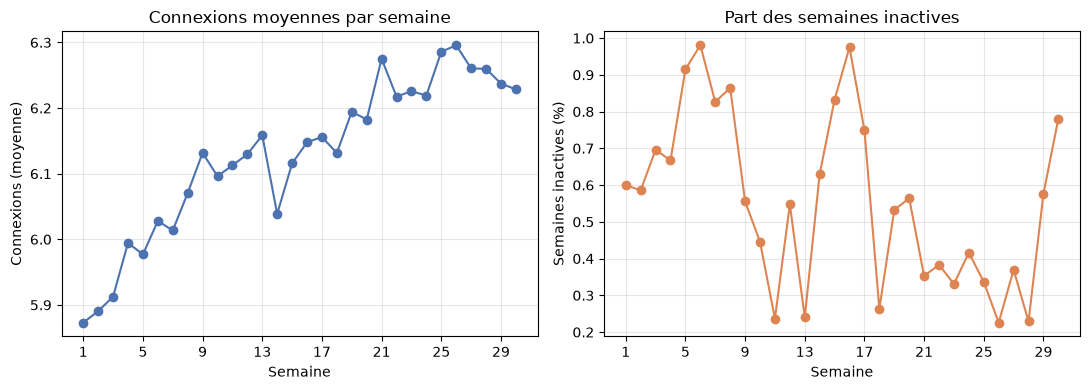

Les étudiants encore suivis se connectent en moyenne 5,87 fois en semaine 1, 6,12 en semaine 15 et 6,23 en semaine 30 (3458 étudiants encore suivis). L'activité moyenne des étudiants encore suivis ne baisse pas au fil de l'année ; une explication probable est que ceux qui décrochent sortent du suivi, si bien que les étudiants restants sont en moyenne plus actifs. La part des semaines inactives reste faible (au plus 1,0 %). Rappel (D-42) : dans un modèle semaine par semaine, seule l'activité des semaines précédentes (colonnes *_prec) pourra servir.


In [7]:
activite = eda.activite_par_semaine(periode)
display(activite.round(2))

figure, (axe_connexions, axe_inactives) = plt.subplots(1, 2, figsize=(11, 4))
axe_connexions.plot(activite["semaine"], activite["connexions_moyennes"], marker="o", color="#4C72B0")
axe_connexions.set_title("Connexions moyennes par semaine")
axe_connexions.set_xlabel("Semaine")
axe_connexions.set_ylabel("Connexions (moyenne)")
axe_inactives.plot(activite["semaine"], activite["pct_inactives"], marker="o", color="#DD8452")
axe_inactives.set_title("Part des semaines inactives")
axe_inactives.set_xlabel("Semaine")
axe_inactives.set_ylabel("Semaines inactives (%)")
for axe in (axe_connexions, axe_inactives):
    axe.set_xticks(range(1, config.N_SEMAINES + 1, 4))
    axe.grid(alpha=0.3)
enregistrer(figure, "02_activite_hebdomadaire.png")

par_semaine = activite.set_index("semaine")
print(f"Les étudiants encore suivis se connectent en moyenne {pct(par_semaine.loc[1, 'connexions_moyennes'], 2)} fois "
      f"en semaine 1, {pct(par_semaine.loc[15, 'connexions_moyennes'], 2)} en semaine 15 et "
      f"{pct(par_semaine.loc[30, 'connexions_moyennes'], 2)} en semaine 30 "
      f"({par_semaine.loc[30, 'suivis']} étudiants encore suivis). L'activité moyenne des étudiants "
      "encore suivis ne baisse pas au fil de l'année ; une explication probable est que ceux qui décrochent sortent "
      "du suivi, si bien que les étudiants restants sont en moyenne plus actifs. "
      f"La part des semaines inactives reste faible (au plus {pct(activite['pct_inactives'].max())} %). "
      "Rappel (D-42) : dans un modèle semaine par semaine, seule l'activité des semaines précédentes (colonnes *_prec) "
      "pourra servir.")

## 6. Moment d'entrée en tutorat

Distribution de la semaine de début du tutorat (semaines connues), motifs d'orientation et types de tuteur. **Aucune donnée de décrochage** n'est utilisée ici : la comparaison tutorés / non tutorés sera faite dans la partie causale, en tenant compte du biais de sélection et du biais du temps immortel.

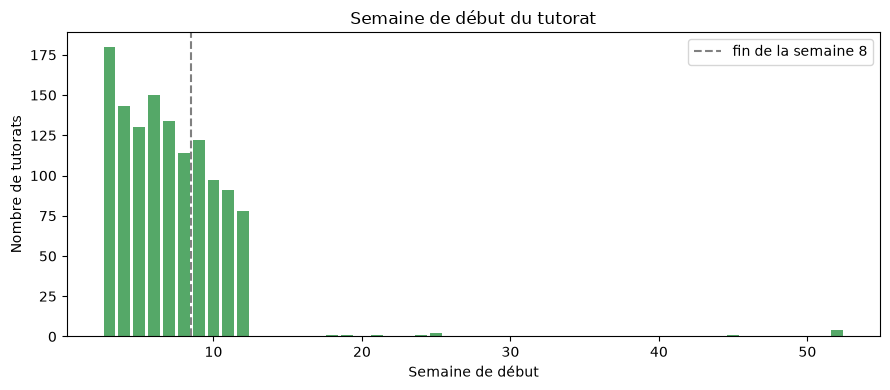

,effectif
motif_orientation,
notes faibles,486
absences répétées,326
signalement enseignant,240
demande personnelle,203


,effectif
type_tuteur,
pair,831
enseignant,424


1255 étudiants ont un tutorat, dont 1250 avec une semaine de début connue. Un quart des tutorats commence au plus tard en semaine 4, la moitié au plus tard en semaine 7 et les trois quarts au plus tard en semaine 9. 851 tutorats (68 %) ont commencé au plus tard en semaine 8 : cette information servira à choisir la semaine landmark en CA-01 (une semaine L tardive classe plus d'étudiants comme tutorés, mais écarte ceux qui ont décroché avant L). Motifs d'orientation : notes faibles (486), absences répétées (326), signalement enseignant (240), demande personnelle (203).


In [8]:
tutorat = eda.debut_tutorat(base)

figure, axe = plt.subplots(figsize=(9, 4))
axe.bar(tutorat["distribution"].index, tutorat["distribution"].values, color="#55A868")
axe.axvline(config.SEMAINE_REPERE_TUTORAT + 0.5, color="grey", linestyle="--",
            label=f"fin de la semaine {config.SEMAINE_REPERE_TUTORAT}")
axe.set_title("Semaine de début du tutorat")
axe.set_xlabel("Semaine de début")
axe.set_ylabel("Nombre de tutorats")
axe.legend()
enregistrer(figure, "02_debut_tutorat.png")

display(tutorat["motifs"].rename("effectif").to_frame())
display(tutorat["types_tuteur"].rename("effectif").to_frame())
q = tutorat["quartiles"]
motifs = ", ".join(f"{motif} ({n})" for motif, n in tutorat["motifs"].items())
print(f"{tutorat['nb_tutorats']} étudiants ont un tutorat, dont {tutorat['nb_connues']} avec une semaine de début connue. "
      f"Un quart des tutorats commence au plus tard en semaine {q[0.25]:.0f}, la moitié au plus tard en semaine {q[0.5]:.0f} "
      f"et les trois quarts au plus tard en semaine {q[0.75]:.0f}. "
      f"{tutorat['nb_au_plus_tard_repere']} tutorats ({pct(tutorat['part_au_plus_tard_repere'], 0)} %) ont commencé au plus "
      f"tard en semaine {config.SEMAINE_REPERE_TUTORAT} : cette information servira à choisir la semaine landmark en CA-01 "
      "(une semaine L tardive classe plus d'étudiants comme tutorés, mais écarte ceux qui ont décroché avant L). "
      f"Motifs d'orientation : {motifs}.")